In [1]:
import sys
sys.path.insert(0, "/Users/ashwanishah/Desktop/AQI/MODEL/Utility_fun")
import aqi_utils as U


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
 # ===== ITO – Part A: Setup, load and tidy =====
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import aqi_utils as U

STATION  = "Bengluru_SILK"
DATA_DIR = "/Users/ashwanishah/Desktop/AQI/DATASETS/Bengluru/"                 
LAT, LON = 12.91694, 77.62180           
FIG = "figures_SILK"
os.makedirs(FIG, exist_ok=True)

# 1. load all files
raw = U.load_cpcb(DATA_DIR)

# 2. tidy: drop empty columns, remove duplicate hours, fill in missing hours
n_before = len(raw)
raw = U.tidy(raw)
print("\nShape:", raw.shape, "| from", raw.index.min(), "to", raw.index.max())
print("Hours in files:", n_before, "| full hourly timeline:", len(raw))

# 3. missing % per column
print("\nMissing % per column:")
print((raw.isna().mean() * 100).round(1).sort_values())

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


files: ['Bengluru-1h-data(SILK)-2023.xlsx', 'Bengluru-1h-data(SILK)-2024.xlsx', 'Bengluru-1h-data(SILK)-2025.xlsx', 'Bengluru-1h-data(SILK)-2026(SEPT).xlsx']

Shape: (32832, 14) | from 2023-01-01 00:00:00 to 2026-09-29 23:00:00
Hours in files: 32783 | full hourly timeline: 32832

Missing % per column:
RH          9.6
AT          9.7
WD          9.8
WS          9.8
PM2.5      10.4
PM10       10.6
SO2        11.3
BENZENE    11.3
TOLUENE    12.0
CO         16.5
NO2        19.3
NH3        19.4
NO         19.5
BP         40.8
dtype: float64


Removed by cleaning (hours) and missing % after:
         negative  flatline  stuck_0.1  missing_%_now
PM2.5           0        39          0           10.6
PM10            0         0          0           10.6
NO              0        62          0           19.7
NO2             0         0         10           19.3
NH3             0        53         16           19.6
SO2             0        23          0           11.4
CO              0       171          0           17.0
BENZENE         0      1914          0           17.2
TOLUENE         0       118          0           12.4


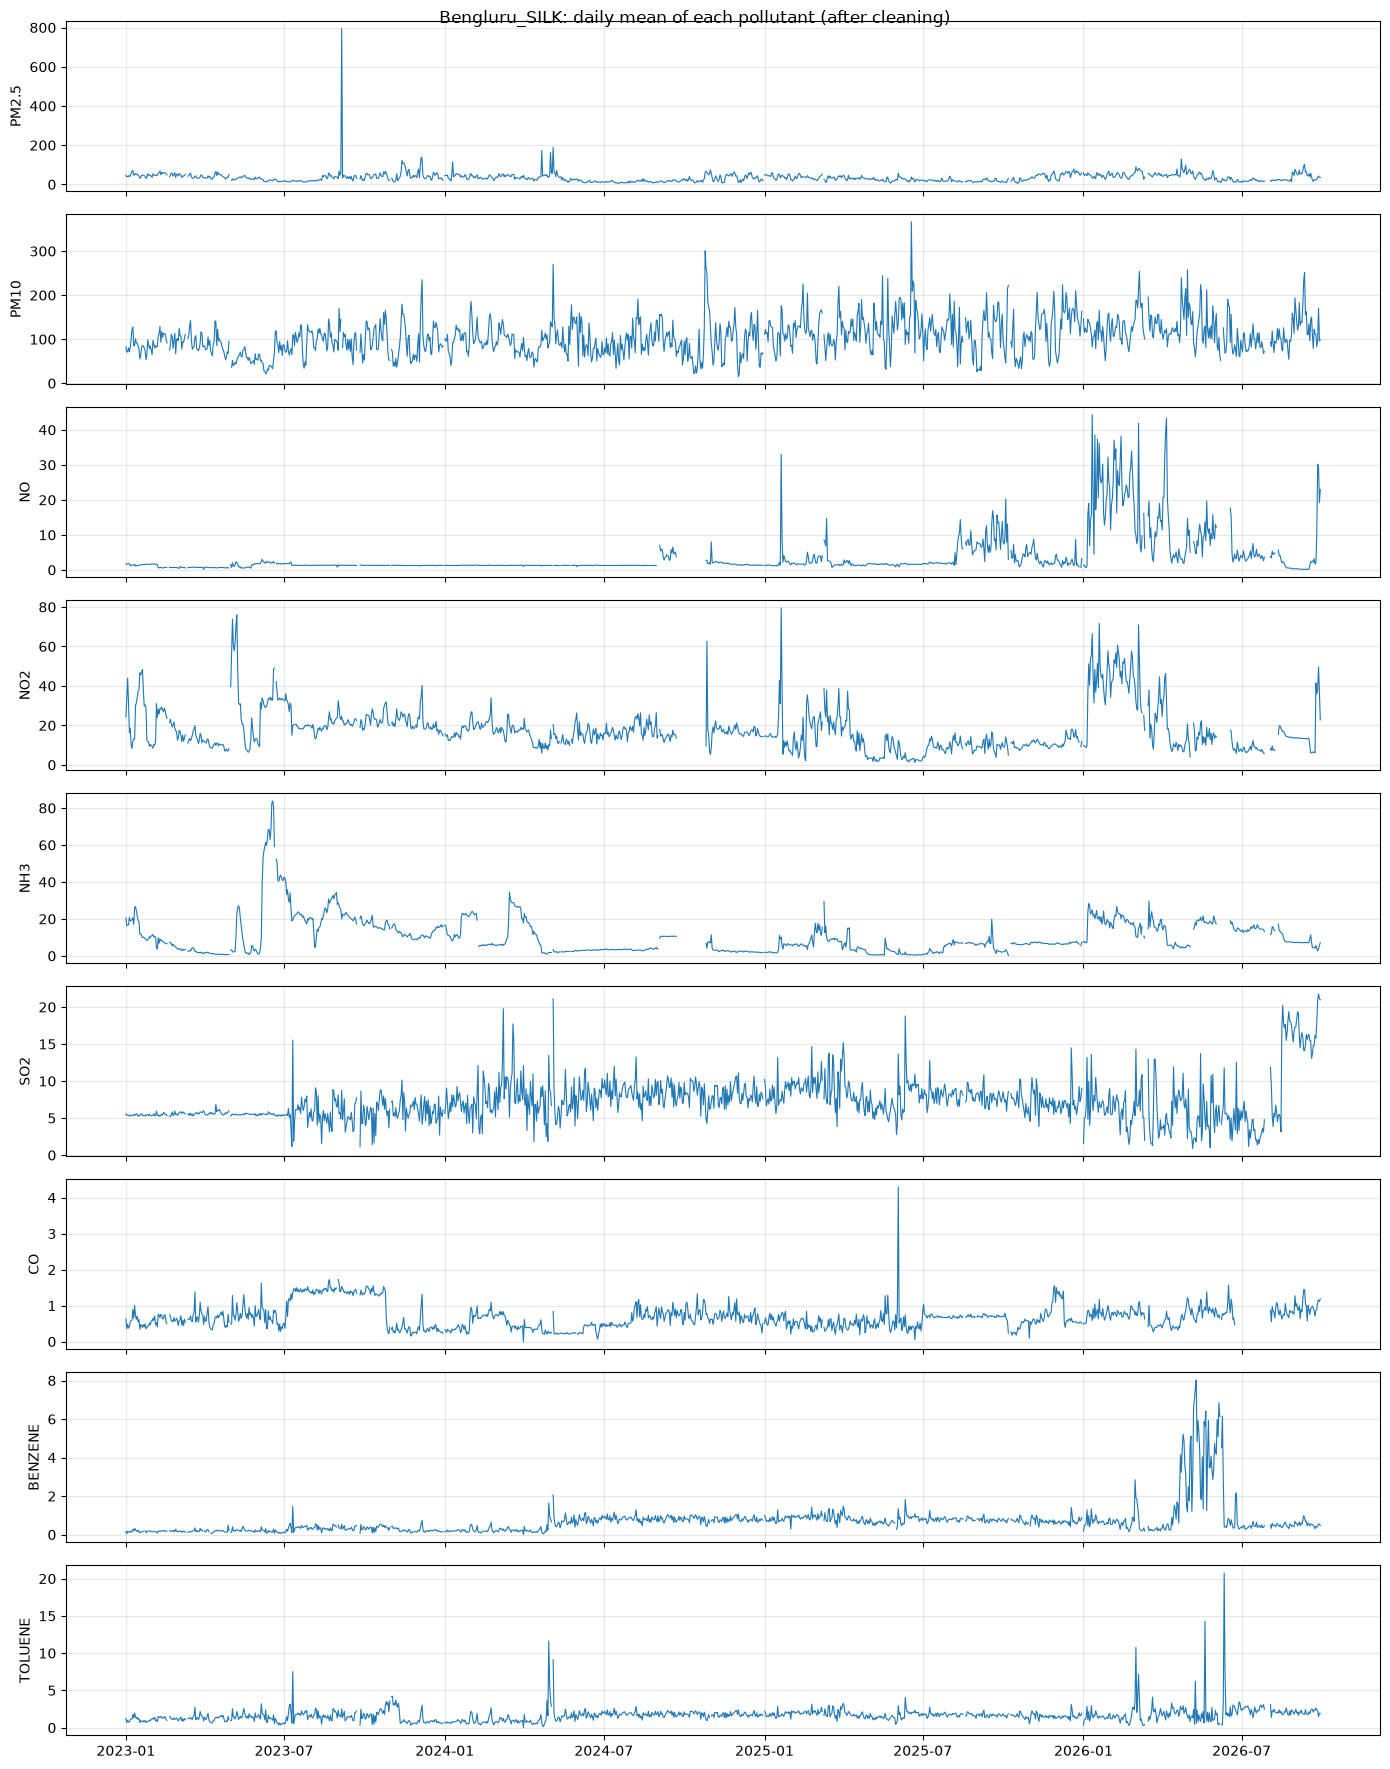

In [3]:
# ===== ITO – Part B: Clean and check the sensors =====
data, qc = U.clean_pollutants(raw)
print("Removed by cleaning (hours) and missing % after:")
print(qc)

# daily mean of each pollutant, 2023–2026
POLS = [p for p in U.ALL_POLS if p in data.columns]
daily = data[POLS].resample("D").mean()

fig, axes = plt.subplots(len(POLS), 1, figsize=(14, 2.0 * len(POLS)), sharex=True)
for ax, p in zip(axes, POLS):
    ax.plot(daily.index, daily[p], lw=0.8)
    ax.set_ylabel(p); ax.grid(alpha=0.3)
plt.suptitle(f"{STATION}: daily mean of each pollutant (after cleaning)")
plt.tight_layout(); plt.savefig(f"{FIG}/pollutants_daily.png", dpi=200); plt.show()

In [4]:
# find the PM2.5 spike day(s) and look at the hours
daily_pm = raw["PM2.5"].resample("D").mean()          # use the raw (uncleaned) data
spikes = daily_pm[daily_pm > 400]
print("Spike days:\n", spikes.round(0))

for d in spikes.index:
    print(f"\nHourly PM2.5 on {d.date()}:")
    print(raw.loc[str(d.date()), "PM2.5"].round(0).to_string())
    print("Neighbouring days (daily mean):",
          daily_pm.loc[d - pd.Timedelta(days=2): d + pd.Timedelta(days=2)].round(0).to_dict())

Spike days:
 time
2023-09-05    794.0
2024-01-09    606.0
2024-01-10    594.0
Name: PM2.5, dtype: float64

Hourly PM2.5 on 2023-09-05:
time
2023-09-05 00:00:00      NaN
2023-09-05 01:00:00      NaN
2023-09-05 02:00:00      NaN
2023-09-05 03:00:00      NaN
2023-09-05 04:00:00      NaN
2023-09-05 05:00:00      NaN
2023-09-05 06:00:00      NaN
2023-09-05 07:00:00      NaN
2023-09-05 08:00:00      NaN
2023-09-05 09:00:00      NaN
2023-09-05 10:00:00    794.0
2023-09-05 11:00:00    794.0
2023-09-05 12:00:00      NaN
2023-09-05 13:00:00      NaN
2023-09-05 14:00:00      NaN
2023-09-05 15:00:00      NaN
2023-09-05 16:00:00      NaN
2023-09-05 17:00:00      NaN
2023-09-05 18:00:00      NaN
2023-09-05 19:00:00      NaN
2023-09-05 20:00:00      NaN
2023-09-05 21:00:00      NaN
2023-09-05 22:00:00      NaN
2023-09-05 23:00:00      NaN
Freq: h
Neighbouring days (daily mean): {Timestamp('2023-09-03 00:00:00'): 47.0, Timestamp('2023-09-04 00:00:00'): 58.0, Timestamp('2023-09-05 00:00:00'): 794.0, Ti

In [5]:
pols = [p for p in daily.columns if p in U.BP]
si = pd.DataFrame({p: U.sub_index(daily[p], p) for p in pols})
leader = si.dropna(how="all").idxmax(axis=1)

for name, a, b in [("CO flat 2023", "2023-07-01", "2023-10-31"),
                   ("CO flat 2025", "2025-07-01", "2025-10-31")]:
    print(f"{name}: CO sets AQI on {(leader.loc[a:b] == 'CO').mean() * 100:.1f}% of days")

CO flat 2023: CO sets AQI on 8.4% of days
CO flat 2025: CO sets AQI on 5.0% of days


In [6]:
# does the AQI category change if CO is left out in its flat periods?
cats = lambda s: pd.cut(s, [-1, 50, 100, 200, 300, 400, 1e9], labels=False)
for name, a, b in [("CO flat 2023", "2023-07-01", "2023-10-31"),
                   ("CO flat 2025", "2025-07-01", "2025-10-31")]:
    s = si.loc[a:b].dropna(how="all")
    with_co = cats(s.max(axis=1))
    without_co = cats(s.drop(columns="CO").max(axis=1))
    print(f"{name}: category changes on {(with_co != without_co).mean() * 100:.1f}% of days")

CO flat 2023: category changes on 5.0% of days
CO flat 2025: category changes on 0.0% of days


In [7]:
# ===== Bengaluru – Part B (decision): keep only reliable pollutants =====
DROPPED = {
    "NO":      "flat (about 1–2) until mid-2024, then jumps to 20–45 in 2026",
    "NO2":     "level drifts: about 2–10 in mid-2025, jumps to 40–70 in early 2026",
    "NH3":     "erratic, flat stretches and gaps",
    "SO2":     "stuck at about 5.5 in Jan–Jun 2023, step up to 15–21 in Aug–Sep 2026",
    "BENZENE": "large spikes in 2026",
    "TOLUENE": "large spikes in 2026",
}
data = data.drop(columns=[c for c in DROPPED if c in data.columns])

# remove impossible PM2.5 spike day(s): daily mean > 400 (Bengaluru otherwise stays below about 200)
daily_pm = data["PM2.5"].resample("D").mean()
spike_days = daily_pm[daily_pm > 400].index
data.loc[data.index.normalize().isin(spike_days), "PM2.5"] = np.nan
print("PM2.5 spike days removed:", [str(d.date()) for d in spike_days])

POLS_ST = [p for p in U.AQI_POLS_ALL if p in data.columns]
print("Kept pollutants:", POLS_ST)
print("Note: CO kept despite flat periods (Jul–Oct 2023, Jul–Oct 2025) – needed for the 3-pollutant AQI minimum")

PM2.5 spike days removed: ['2023-09-05']
Kept pollutants: ['PM2.5', 'PM10', 'CO']
Note: CO kept despite flat periods (Jul–Oct 2023, Jul–Oct 2025) – needed for the 3-pollutant AQI minimum


In [8]:
# ===== ITO – Part C: ERA5 weather =====
met = U.get_era5(LAT, LON,
                 str(data.index.min().date()), str(data.index.max().date()),
                 cache_file="era5_silk.csv")
print("ERA5:", met.shape, met.index.min(), "to", met.index.max())
print("Missing %:", (met.isna().mean() * 100).round(1).to_dict())

data = U.use_era5(data, met)
print("\nColumns now:", list(data.columns))
print("Shape:", data.shape)

ERA5: (32832, 8) 2023-01-01 00:00:00 to 2026-09-29 23:00:00
Missing %: {'temperature_2m': 0.0, 'relative_humidity_2m': 0.0, 'shortwave_radiation': 0.0, 'precipitation': 0.0, 'wind_speed_10m': 0.0, 'wind_direction_10m': 0.0, 'surface_pressure': 0.0, 'cloud_cover': 0.0}

Columns now: ['PM2.5', 'PM10', 'CO', 'AT', 'RH', 'SR', 'RF', 'wind_speed_10m', 'WD', 'surface_pressure', 'cloud_cover']
Shape: (32832, 11)


In [9]:
# ===== ITO – Part D: Daily values, AQI, features =====
Y = U.make_daily_conc(data, POLS_ST)                     # daily concentrations (targets)
X = U.build_features(data, Y, POLS_ST)                   # inputs
pers = pd.DataFrame({p: X[f"{p}_lag1"] for p in POLS_ST})  # persistence

aqi_true = U.compute_aqi(Y, POLS_ST)
aqi_cat  = U.to_cat(aqi_true)
print("X:", X.shape, "| Y:", Y.shape)
print("Days with an AQI:", aqi_true.notna().sum(), "of", len(aqi_true))

# categories in each period
check = pd.DataFrame({s: aqi_cat[U.in_period(aqi_cat.index, s) & aqi_true.notna()].value_counts().reindex(U.CATS)
                      for s in U.SPLITS}).fillna(0).astype(int)
check.loc["total days"] = check.sum()
print("\nAQI categories per period:")
print(check)

# which pollutant decides the AQI
sub = pd.DataFrame({p: U.sub_index(Y[p], p) for p in POLS_ST})
print("\nWhich pollutant decides the AQI (% of days):")
print((sub[aqi_true.notna()].idxmax(axis=1).value_counts(normalize=True) * 100).round(1))

X: (1368, 25) | Y: (1368, 3)
Days with an AQI: 1101 of 1368

AQI categories per period:
              train  val  test  test2
Good             17    9    17      0
Satisfactory    342   39    66     45
Moderate        206   34   173    136
Poor              4    2     0      5
Very Poor         5    0     0      1
Severe            0    0     0      0
total days      574   84   256    187

Which pollutant decides the AQI (% of days):
PM10     88.4
CO        7.9
PM2.5     3.7
Name: proportion, dtype: float64


In [10]:
# ===== ITO – Part E: Own model vs persistence (N2) =====
with open("/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved/final_params.json") as f:   # adjust path if needed
    FINAL_PARAMS = json.load(f)

FINAL_MODELS = ["Lasso", "ExtraTrees", "LightGBM", "HistGB"]
SEEDS = [0, 1, 2, 3, 4]
fit   = X.index <= "2024-12-31"
test  = U.in_period(X.index, "test")
test2 = U.in_period(X.index, "test2")

own_preds = {}
for name in FINAL_MODELS:
    own_preds[name] = [U.forecast(X[fit], Y[fit], X, POLS_ST, name, {**FINAL_PARAMS[name], "random_state": s})
                       for s in SEEDS]
    print("done:", name)

for label, days in [("Test 2025", test), ("Test Jan–Sep 2026", test2)]:
    rows = [{"model": "Persistence", **U.scores(pers, days, Y, pers, POLS_ST)}]
    for name in FINAL_MODELS:
        sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_ST) for p in own_preds[name]])
        rows.append({"model": name, "days": sc.days.iloc[0],
                     "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                     "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3)})
    print(f"\n{STATION} – {label} (own model, mean of 5 seeds):")
    print(pd.DataFrame(rows).to_string(index=False))

    ci_rows = [{"model": name, **U.gain_ci(own_preds[name], days, Y, pers, POLS_ST)} for name in FINAL_MODELS]
    print(f"\nGain over persistence, {label}:")
    print(pd.DataFrame(ci_rows).to_string(index=False))

done: Lasso
done: ExtraTrees
done: LightGBM
done: HistGB

Bengluru_SILK – Test 2025 (own model, mean of 5 seeds):
      model  days  accuracy  macro_F1  PM2.5_skill  PM10_skill
Persistence   205     0.702     0.584        0.000       0.000
      Lasso   205     0.663     0.473        0.016       0.139
 ExtraTrees   205     0.635     0.490        0.095       0.029
   LightGBM   205     0.557     0.421       -0.041      -0.135
     HistGB   205     0.620     0.453       -0.067      -0.044

Gain over persistence, Test 2025:
     model  days  acc_gain    acc_gain_95CI  F1_gain     F1_gain_95CI  P(F1_gain>0)
     Lasso   205    -0.039 [-0.098, +0.020]   -0.111 [-0.227, +0.052]         0.091
ExtraTrees   205    -0.067 [-0.134, -0.002]   -0.095 [-0.175, +0.007]         0.033
  LightGBM   205    -0.145 [-0.225, -0.056]   -0.163 [-0.302, +0.032]         0.054
    HistGB   205    -0.083 [-0.156, +0.010]   -0.130 [-0.266, +0.078]         0.104

Bengluru_SILK – Test Jan–Sep 2026 (own model, mean o

In [11]:
# ===== ITO – Part F: Leaky vs honest classifier (N1) =====
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def rf_clf():
    return Pipeline([("fill", SimpleImputer(strategy="median")),
                     ("model", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))])

y_cls  = aqi_cat
has    = aqi_true.notna()
X_leak = Y.join(X[U.WEATHER_COLS + U.CALENDAR_COLS])          # TODAY's pollutants + weather + calendar

leaky  = rf_clf().fit(X_leak[fit & has], y_cls[fit & has])
honest = rf_clf().fit(X[fit & has],      y_cls[fit & has])

# same test days for every method
a_pers = U.compute_aqi(pers, POLS_ST)
a_ours = U.compute_aqi(own_preds["ExtraTrees"][0], POLS_ST)
days = X.index[test & has & a_pers.notna() & a_ours.notna()]

methods = {"Leaky classifier (same-day pollutants)": leaky.predict(X_leak.loc[days]),
           "CPCB formula on same-day values":        y_cls[days].values,
           "Persistence":                            U.to_cat(a_pers[days]).values,
           "Honest direct classifier":               honest.predict(X.loc[days]),
           "Our route: ExtraTrees + CPCB formula":   U.to_cat(a_ours[days]).values}
rows = [{"method": m, "accuracy": round(accuracy_score(y_cls[days], p), 3),
         "macro_F1": round(U.macro_f1(y_cls[days].values, p), 3)} for m, p in methods.items()]
print(f"{STATION} – test 2025, {len(days)} days:")
print(pd.DataFrame(rows).to_string(index=False))

# where are the leaky model's mistakes?
wrong = methods["Leaky classifier (same-day pollutants)"] != y_cls[days].values
dist = aqi_true[days].apply(lambda a: np.abs(np.array([50, 100, 200, 300, 400]) - a).min())
print(f"\nLeaky mistakes: {wrong.sum()} | median distance to boundary: wrong {dist[wrong].median():.1f}, "
      f"correct {dist[~wrong].median():.1f} | within 15 points: {(dist[wrong] <= 15).mean():.0%}")
part_f = pd.DataFrame(rows).set_index("method")

Bengluru_SILK – test 2025, 205 days:
                                method  accuracy  macro_F1
Leaky classifier (same-day pollutants)     0.946     0.751
       CPCB formula on same-day values     1.000     1.000
                           Persistence     0.702     0.584
              Honest direct classifier     0.580     0.390
  Our route: ExtraTrees + CPCB formula     0.624     0.457

Leaky mistakes: 11 | median distance to boundary: wrong 10.3, correct 14.6 | within 15 points: 100%


In [12]:
import importlib; importlib.reload(U)

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
U.leak_tests(obs_cat   = y_cls[days].values,
             leaky_cat = methods["Leaky classifier (same-day pollutants)"],
             our_cat   = methods["Our route: ExtraTrees + CPCB formula"],
             obs_aqi   = aqi_true[days],
             station   = STATION,
             out_dir   = SUMMARY_DIR)

Bengluru_SILK: errors n=11 | boundary Mann–Whitney p = 0.0152 | McNemar leaky vs day-ahead p = 4.68e-19


{'station': 'Bengluru_SILK',
 'n_errors': 11,
 'p_boundary': np.float64(0.015169634015220094),
 'p_mcnemar': np.float64(4.675621868843738e-19)}

In [13]:
# ===== ITO – Part G: Transfer from Delhi (N3) + 5-pollutant check at Delhi =====
SAVE = "/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved"          # adjust if needed
Xd = pd.read_csv(f"{SAVE}/delhi_X.csv", index_col=0, parse_dates=True)
Yd = pd.read_csv(f"{SAVE}/delhi_Y.csv", index_col=0, parse_dates=True)

POLS_T = [p for p in POLS_ST if p in Yd.columns]                 # pollutants both stations have
FEATS  = [c for c in X.columns if c in Xd.columns]                # inputs both stations have
print("Shared pollutants:", POLS_T)
print("Shared inputs:", len(FEATS), "| ITO inputs missing in Delhi:", [c for c in X.columns if c not in Xd.columns])

ET    = FINAL_PARAMS["ExtraTrees"]
d_fit = Xd.index <= "2024-12-31"
LOCAL = {1: "2024-12-01", 2: "2024-11-01", 3: "2024-10-01"}
W     = 10                                                        # weight of local rows

def train_predict(X_tr, Y_tr, X_pred):
    return [U.forecast(X_tr, Y_tr, X_pred, POLS_T, "ExtraTrees", {**ET, "random_state": s}) for s in SEEDS]

# ---------- 1. transfer to ITO ----------
setups = {"Own ITO model (ITO 2023–24)": [p[POLS_T] for p in own_preds["ExtraTrees"]],
          "Zero-shot (Delhi only)":       train_predict(Xd.loc[d_fit, FEATS], Yd.loc[d_fit, POLS_T], X[FEATS])}
for k, start in LOCAL.items():
    lm = (X.index >= start) & (X.index <= "2024-12-31")
    X_tr = pd.concat([Xd.loc[d_fit, FEATS]] + [X.loc[lm, FEATS]] * W)
    Y_tr = pd.concat([Yd.loc[d_fit, POLS_T]] + [Y.loc[lm, POLS_T]] * W)
    setups[f"Few-shot: Delhi + {k} month(s) of ITO"] = train_predict(X_tr, Y_tr, X[FEATS])
    print("done: few-shot", k)

rows = [{"setup": "Persistence", **U.scores(pers, test, Y, pers, POLS_T)}]
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test, Y, pers, POLS_T) for p in preds])
    ci = U.gain_ci(preds, test, Y, pers, POLS_T)
    rows.append({"setup": name, "days": sc.days.iloc[0],
                 "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                 "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3),
                 "acc_gain_95CI": ci["acc_gain_95CI"], "F1_gain_95CI": ci["F1_gain_95CI"]})
transfer_ito = pd.DataFrame(rows)
print(f"\nTransfer Delhi -> {STATION}, test 2025:")
print(transfer_ito.to_string(index=False))

# ---------- 2. check: Delhi's own 2025 with only these 5 pollutants ----------
pers_d = pd.DataFrame({p: Xd[f"{p}_lag1"] for p in POLS_T})
d_test = U.in_period(Xd.index, "test")
d5 = train_predict(Xd.loc[d_fit, FEATS], Yd.loc[d_fit, POLS_T], Xd[FEATS])
sc = pd.DataFrame([U.scores(p, d_test, Yd, pers_d, POLS_T) for p in d5])
ci = U.gain_ci(d5, d_test, Yd, pers_d, POLS_T)
print("\nCheck – R K Puram 2025 with only the 5 shared pollutants (ExtraTrees):")
print(f"persistence acc {U.scores(pers_d, d_test, Yd, pers_d, POLS_T)['accuracy']} | "
      f"model acc {sc.accuracy.mean():.3f} | acc gain {ci['acc_gain']:+.3f} {ci['acc_gain_95CI']} | "
      f"PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")

Shared pollutants: ['PM2.5', 'PM10', 'CO']
Shared inputs: 25 | ITO inputs missing in Delhi: []
done: few-shot 1
done: few-shot 2
done: few-shot 3

Transfer Delhi -> Bengluru_SILK, test 2025:
                              setup  days  accuracy  macro_F1  PM2.5_skill  PM10_skill    acc_gain_95CI     F1_gain_95CI
                        Persistence   205     0.702     0.584        0.000       0.000              NaN              NaN
        Own ITO model (ITO 2023–24)   205     0.635     0.490        0.095       0.029 [-0.134, -0.002] [-0.175, +0.007]
             Zero-shot (Delhi only)   205     0.626     0.387       -6.889      -0.077 [-0.159, +0.003] [-0.299, -0.054]
Few-shot: Delhi + 1 month(s) of ITO   205     0.579     0.392       -0.554      -0.228 [-0.221, -0.032] [-0.307, -0.040]
Few-shot: Delhi + 2 month(s) of ITO   205     0.569     0.429       -0.048      -0.299 [-0.240, -0.040] [-0.294, +0.007]
Few-shot: Delhi + 3 month(s) of ITO   205     0.609     0.483        0.068      -0.

In [15]:
# ===== Part H: Save summary row (generic – works in every station notebook) =====
from sklearn.metrics import accuracy_score

# 1. distance from R K Puram and ring
SRC_LAT, SRC_LON = 28.5633, 77.1869               # R K Puram – use the exact LAT/LON from the Delhi notebook
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

DIST = round(float(haversine_km(SRC_LAT, SRC_LON, LAT, LON)), 1)
RING = ("Ring 0 (< 50 km)" if DIST < 50 else
        "Ring 1 (150–600 km)" if 150 <= DIST <= 600 else
        "Ring 2 (> 1000 km)" if DIST > 1000 else "between rings")

# 2. leaky and honest accuracy, recomputed on the Part F test days
a_pers_h = U.compute_aqi(pers, POLS_ST)
a_ours_h = U.compute_aqi(own_preds["ExtraTrees"][0], POLS_ST)
days_f   = X.index[test & aqi_true.notna() & a_pers_h.notna() & a_ours_h.notna()]
leaky_acc  = round(accuracy_score(aqi_cat[days_f], leaky.predict(X_leak.loc[days_f])), 3)
honest_acc = round(accuracy_score(aqi_cat[days_f], honest.predict(X.loc[days_f])), 3)

# 3. transfer setups, found by name (works whatever the labels say)
def find(prefix):
    return next(k for k in setups if k.startswith(prefix))
keys = {"own": find("Own"), "zero": find("Zero")}
for k in [1, 2, 3]:
    keys[f"few{k}"] = next(s for s in setups if s.startswith("Few") and f"{k} month" in s)

def mean_scores(preds, days):
    sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_T) for p in preds])
    return sc.accuracy.mean().round(3), sc.macro_F1.mean().round(3), sc["PM2.5_skill"].mean().round(3)

T = transfer_ito                                   # the Part G transfer table in this notebook
row = {"station": STATION, "lat": LAT, "lon": LON, "ring": RING, "distance_km": DIST,
       "pollutants_used": ", ".join(POLS_ST), "dropped": ", ".join(DROPPED),
       "test_days": int(T.loc[0, "days"]),
       "persistence_acc": T.loc[0, "accuracy"], "persistence_F1": T.loc[0, "macro_F1"],
       "leaky_acc": leaky_acc, "honest_acc": honest_acc}
for key, name in keys.items():
    acc, f1, sk = mean_scores(setups[name], test)
    row[f"{key}_acc"], row[f"{key}_F1"], row[f"{key}_PM25_skill"] = acc, f1, sk

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
os.makedirs(SUMMARY_DIR, exist_ok=True)
pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)
print(pd.Series(row))

station                                  Bengluru_SILK
lat                                           12.91694
lon                                            77.6218
ring                                Ring 2 (> 1000 km)
distance_km                                     1740.4
pollutants_used                        PM2.5, PM10, CO
dropped            NO, NO2, NH3, SO2, BENZENE, TOLUENE
test_days                                          205
persistence_acc                                  0.702
persistence_F1                                   0.584
leaky_acc                                        0.946
honest_acc                                        0.58
own_acc                                          0.635
own_F1                                            0.49
own_PM25_skill                                   0.095
zero_acc                                         0.626
zero_F1                                          0.387
zero_PM25_skill                                 -6.889
few1_acc  

In [36]:
# ===== Bengaluru – Part H: Save summary row + files for the summary notebook =====
import re

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"          # the shared summary folder
os.makedirs(SUMMARY_DIR, exist_ok=True)

transfer_table = transfer_ito                                       # your transfer table in this notebook

def distance_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

DIST = int(round(distance_km(28.5633, 77.1869, LAT, LON)))
RING = "Ring 0 (same city)" if DIST < 50 else "Ring 1 (regional)" if DIST <= 600 else "Ring 2 (distant)"

tt = transfer_table.set_index("setup")
own_key  = next(k for k in tt.index if k.startswith("Own"))
zero_key = next(k for k in tt.index if k.startswith("Zero"))
few_keys = sorted([k for k in tt.index if k.startswith("Few")], key=lambda k: int(re.search(r"(\d+)\s*month", k).group(1)))

row = {"station": STATION, "ring": RING, "distance_km": DIST,
       "pollutants_used": ", ".join(POLS_T), "dropped": ", ".join(DROPPED),
       "test_days": int(tt.loc["Persistence", "days"]),
       "persistence_acc": tt.loc["Persistence", "accuracy"], "persistence_F1": tt.loc["Persistence", "macro_F1"],
       "leaky_acc":  part_f.loc["Leaky classifier (same-day pollutants)", "accuracy"],
       "honest_acc": part_f.loc["Honest direct classifier", "accuracy"]}
for key, name in [("own", own_key), ("zero", zero_key)] + [(f"few{i + 1}", k) for i, k in enumerate(few_keys)]:
    row[f"{key}_acc"], row[f"{key}_F1"] = tt.loc[name, "accuracy"], tt.loc[name, "macro_F1"]
    row[f"{key}_PM25_skill"], row[f"{key}_PM10_skill"] = tt.loc[name, "PM2.5_skill"], tt.loc[name, "PM10_skill"]

pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)
X.to_csv(f"{SUMMARY_DIR}/X_{STATION}.csv")
Y.to_csv(f"{SUMMARY_DIR}/daily_{STATION}.csv")
transfer_table.to_csv(f"{SUMMARY_DIR}/transfer_{STATION}.csv", index=False)

print(pd.Series(row).to_string())
print(f"\nSaved 4 files for {STATION} in {SUMMARY_DIR}")

station                                  Bengluru_SILK
ring                                  Ring 2 (distant)
distance_km                                       1740
pollutants_used                        PM2.5, PM10, CO
dropped            NO, NO2, NH3, SO2, BENZENE, TOLUENE
test_days                                          205
persistence_acc                                  0.702
persistence_F1                                   0.584
leaky_acc                                        0.946
honest_acc                                        0.58
own_acc                                          0.635
own_F1                                            0.49
own_PM25_skill                                   0.095
own_PM10_skill                                   0.029
zero_acc                                         0.626
zero_F1                                          0.387
zero_PM25_skill                                 -6.889
zero_PM10_skill                                 -0.077
few1_acc  

In [18]:
transfer_table = transfer_ito        # or whatever the table is called in that notebook

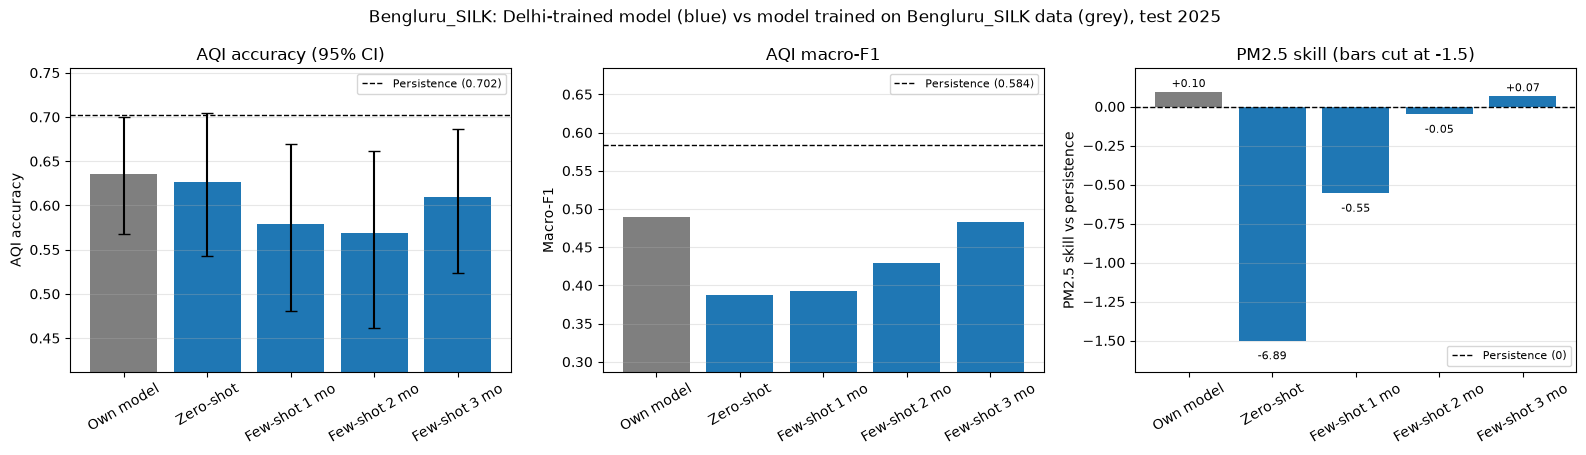

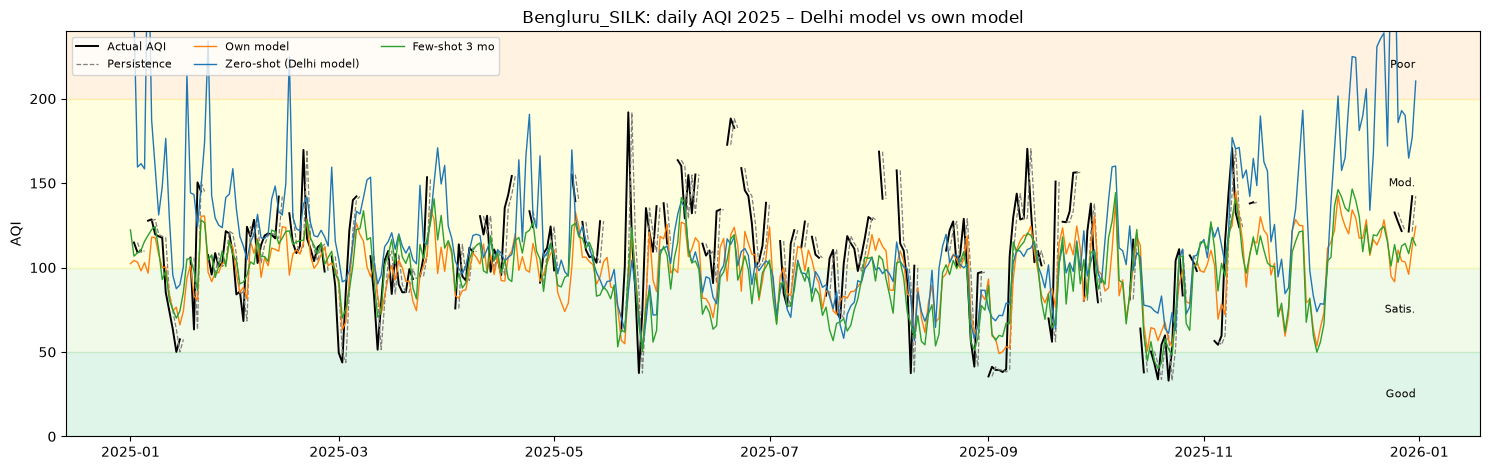

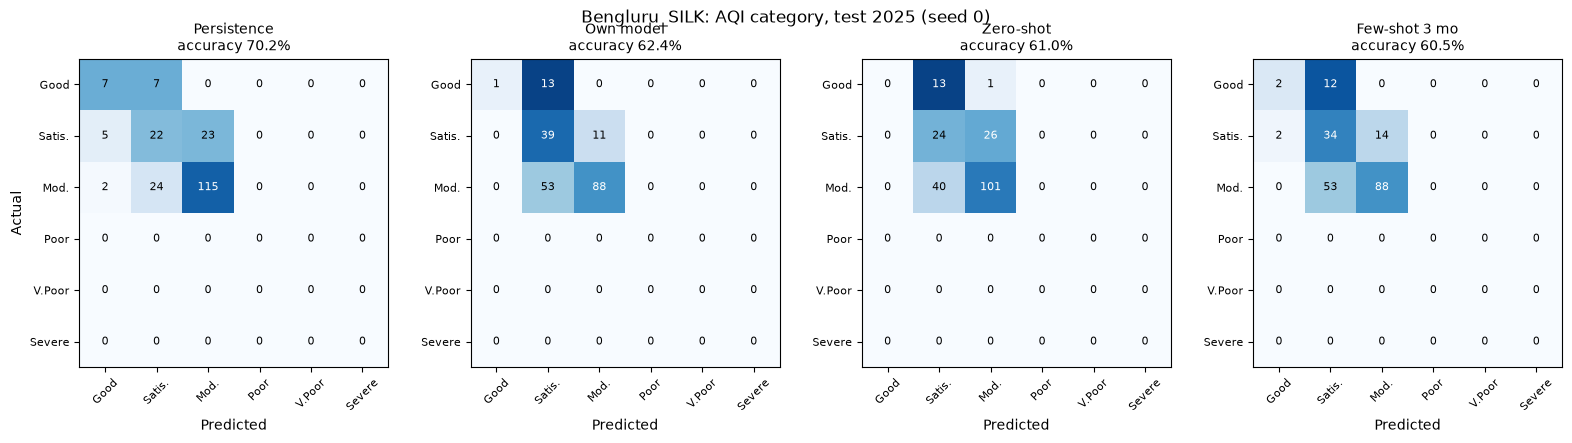

In [22]:
# ===== Part G plots: Delhi-trained model vs own model (works for every station) =====
import re
from sklearn.metrics import confusion_matrix

SHORT   = ["Good", "Satis.", "Mod.", "Poor", "V.Poor", "Severe"]
BANDS   = [0, 50, 100, 200, 300, 400, 500]
COLOURS = ["#00b050", "#92d050", "#ffff00", "#ff9900", "#ff0000", "#c00000"]
SKILL_FLOOR = -1.5                                         # skill below this is cut off (value still printed)

def short_name(n):
    if n.startswith("Own"):       return "Own model"
    if n.startswith("Zero"):      return "Zero-shot"
    m = re.search(r"(\d+)\s*month", n)
    return f"Few-shot {m.group(1)} mo" if m else n

def plot_transfer(station, setups, table, Y, pers, pols, test, fig_dir):
    names    = list(setups.keys())
    own_key  = next(n for n in names if n.startswith("Own"))
    zero_key = next(n for n in names if n.startswith("Zero"))
    few_keys = [n for n in names if n.startswith("Few")]
    labels   = [short_name(n) for n in names]
    t = table.set_index("setup")
    pers_acc, pers_f1 = t.loc["Persistence", "accuracy"], t.loc["Persistence", "macro_F1"]
    bar_col = ["#7f7f7f" if n == own_key else "#1f77b4" for n in names]

    # ---- 1. scores by setup ----
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    acc = np.array([t.loc[n, "accuracy"] for n in names])
    ci  = np.array([list(map(float, t.loc[n, "acc_gain_95CI"].strip("[]").split(","))) for n in names])
    lo, hi = pers_acc + ci[:, 0], pers_acc + ci[:, 1]
    axes[0].bar(labels, acc, color=bar_col, yerr=[acc - lo, hi - acc], capsize=4)
    axes[0].axhline(pers_acc, color="black", ls="--", lw=1, label=f"Persistence ({pers_acc:.3f})")
    axes[0].set_ylim(min(lo.min(), pers_acc) - 0.05, max(hi.max(), pers_acc) + 0.05)
    axes[0].set_ylabel("AQI accuracy"); axes[0].set_title("AQI accuracy (95% CI)")

    f1 = np.array([t.loc[n, "macro_F1"] for n in names])
    axes[1].bar(labels, f1, color=bar_col)
    axes[1].axhline(pers_f1, color="black", ls="--", lw=1, label=f"Persistence ({pers_f1:.3f})")
    axes[1].set_ylim(min(f1.min(), pers_f1) - 0.1, max(f1.max(), pers_f1) + 0.1)
    axes[1].set_ylabel("Macro-F1"); axes[1].set_title("AQI macro-F1")

    sk = np.array([t.loc[n, "PM2.5_skill"] for n in names])
    bars = axes[2].bar(labels, np.maximum(sk, SKILL_FLOOR), color=bar_col)
    for b, v in zip(bars, sk):                              # print the real value on each bar
        axes[2].text(b.get_x() + b.get_width() / 2, max(v, SKILL_FLOOR) + (0.03 if v >= 0 else -0.12),
                     f"{v:+.2f}", ha="center", fontsize=8)
    axes[2].axhline(0, color="black", ls="--", lw=1, label="Persistence (0)")
    axes[2].set_ylim(min(sk.min(), 0) if sk.min() > SKILL_FLOOR else SKILL_FLOOR - 0.2, max(sk.max(), 0) + 0.15)
    axes[2].set_ylabel("PM2.5 skill vs persistence")
    axes[2].set_title("PM2.5 skill" + (f" (bars cut at {SKILL_FLOOR})" if sk.min() < SKILL_FLOOR else ""))
    for ax in axes:
        ax.tick_params(axis="x", rotation=30); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
    plt.suptitle(f"{station}: Delhi-trained model (blue) vs model trained on {station} data (grey), test 2025")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_scores.png", dpi=800); plt.show()

    # ---- 2. AQI over 2025 ----
    a_true = U.compute_aqi(Y, pols)
    top = min(550, np.nanmax(a_true[test]) * 1.25)
    fig, ax = plt.subplots(figsize=(15, 4.8))
    d = Y.index[test]
    for lo_b, hi_b, c, lab in zip(BANDS[:-1], BANDS[1:], COLOURS, SHORT):
        if lo_b < top:
            ax.axhspan(lo_b, hi_b, color=c, alpha=0.12)
            ax.text(d[-1], (lo_b + min(hi_b, top)) / 2, lab, fontsize=8, va="center", ha="right")
    ax.plot(a_true[test].asfreq("D"), color="black", lw=1.4, label="Actual AQI")
    ax.plot(U.compute_aqi(pers, pols)[test].asfreq("D"), color="grey", lw=0.9, ls="--", label="Persistence")
    ax.plot(U.compute_aqi(setups[own_key][0], pols)[test].asfreq("D"), color="tab:orange", lw=1, label="Own model")
    ax.plot(U.compute_aqi(setups[zero_key][0], pols)[test].asfreq("D"), color="tab:blue", lw=1, label="Zero-shot (Delhi model)")
    if few_keys:
        ax.plot(U.compute_aqi(setups[few_keys[-1]][0], pols)[test].asfreq("D"), color="tab:green", lw=1,
                label=short_name(few_keys[-1]))
    ax.set_ylim(0, top); ax.set_ylabel("AQI"); ax.legend(fontsize=8, loc="upper left", ncol=3)
    ax.set_title(f"{station}: daily AQI 2025 – Delhi model vs own model")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_aqi_2025.png", dpi=800); plt.show()

    # ---- 3. confusion matrices ----
    show = {"Persistence": pers, "Own model": setups[own_key][0], "Zero-shot": setups[zero_key][0]}
    if few_keys:
        show[short_name(few_keys[-1])] = setups[few_keys[-1]][0]
    a_all = {k: U.compute_aqi(v, pols) for k, v in show.items()}
    ok = test & a_true.notna()
    for a in a_all.values():
        ok &= a.notna()
    code = {c: i for i, c in enumerate(U.CATS)}
    yt = U.to_cat(a_true[ok]).map(code).values
    fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 4.2))
    for ax, (name, a) in zip(axes, a_all.items()):
        yp = U.to_cat(a[ok]).map(code).values
        cm = confusion_matrix(yt, yp, labels=range(6))
        pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
        for i in range(6):
            for j in range(6):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if pct[i, j] > 50 else "black")
        ax.set_title(f"{name}\naccuracy {(yt == yp).mean():.1%}", fontsize=10)
        ax.set_xticks(range(6)); ax.set_xticklabels(SHORT, rotation=45, fontsize=8)
        ax.set_yticks(range(6)); ax.set_yticklabels(SHORT, fontsize=8); ax.set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    plt.suptitle(f"{station}: AQI category, test 2025 (seed 0)")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_confusion.png", dpi=800); plt.show()

plot_transfer(STATION, setups, transfer_table, Y, pers, POLS_T, test, FIG)

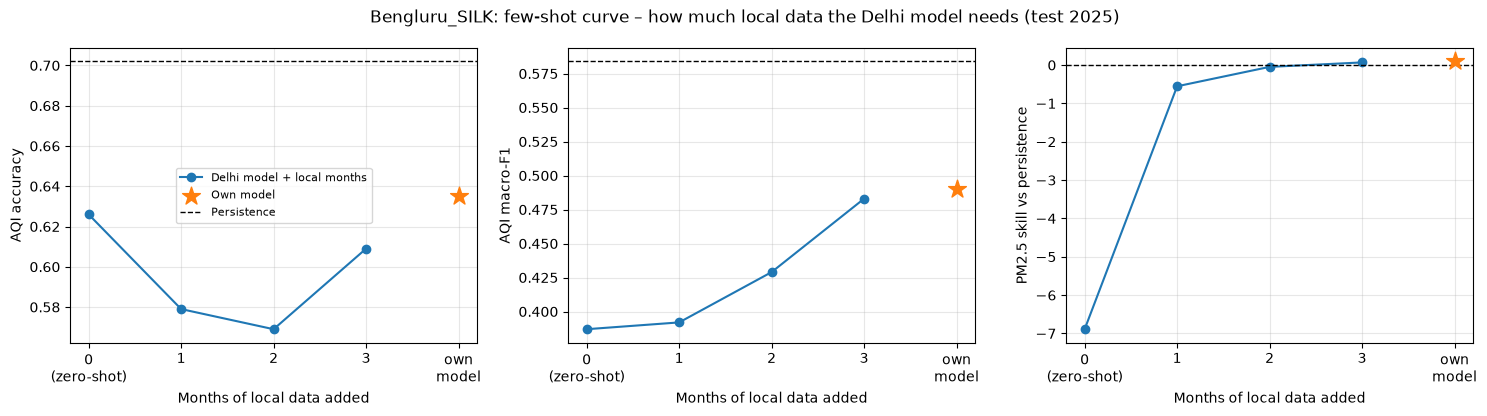

In [24]:
# ===== ITO – Part G plot: few-shot curve (0 -> 1 -> 2 -> 3 months of local data) =====
def plot_fewshot(station, table, zero_key, few_keys, own_key, fig_dir):
    t = table.set_index("setup")
    steps = [zero_key] + few_keys
    x = [0, 1, 2, 3]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (col, lab, base) in zip(axes, [("accuracy", "AQI accuracy", t.loc["Persistence", "accuracy"]),
                                           ("macro_F1", "AQI macro-F1", t.loc["Persistence", "macro_F1"]),
                                           ("PM2.5_skill", "PM2.5 skill vs persistence", 0)]):
        ax.plot(x, [t.loc[s, col] for s in steps], marker="o", color="tab:blue", label="Delhi model + local months")
        ax.scatter([4], [t.loc[own_key, col]], marker="*", s=180, color="tab:orange", zorder=5, label="Own model")
        ax.axhline(base, color="black", ls="--", lw=1, label="Persistence")
        ax.set_xticks([0, 1, 2, 3, 4]); ax.set_xticklabels(["0\n(zero-shot)", "1", "2", "3", "own\nmodel"])
        ax.set_xlabel("Months of local data added"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.suptitle(f"{station}: few-shot curve – how much local data the Delhi model needs (test 2025)")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/fewshot_curve.png", dpi=300); plt.show()

plot_fewshot(STATION, transfer_ito,
             zero_key="Zero-shot (Delhi only)",
             few_keys=["Few-shot: Delhi + 1 month(s) of ITO",
                       "Few-shot: Delhi + 2 month(s) of ITO",
                       "Few-shot: Delhi + 3 month(s) of ITO"],
             own_key="Own ITO model (ITO 2023–24)",
             fig_dir=FIG)

In [25]:
pd.DataFrame({name: U.skill_per_pollutant(preds[0], test, Y, pers, POLS_T)
              for name, preds in setups.items()}).T

,PM2.5,PM10,CO
Own ITO model (ITO 2023–24),0.11,0.03,0.04
Zero-shot (Delhi only),-7.98,-0.12,-0.71
Few-shot: Delhi + 1 month(s) of ITO,-0.61,-0.18,-0.53
Few-shot: Delhi + 2 month(s) of ITO,0.02,-0.32,-0.65
Few-shot: Delhi + 3 month(s) of ITO,0.06,-0.13,-0.61


In [27]:
# ===== ITO – Part G (second check): transfer scored on Jan–Sep 2026 =====
rows = [{"setup": "Persistence", **U.scores(pers, test2, Y, pers, POLS_T)}]
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test2, Y, pers, POLS_T) for p in preds])
    ci = U.gain_ci(preds, test2, Y, pers, POLS_T)
    rows.append({"setup": name, "days": sc.days.iloc[0],
                 "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                 "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3),
                 "acc_gain_95CI": ci["acc_gain_95CI"], "F1_gain_95CI": ci["F1_gain_95CI"]})
transfer_ito_2026 = pd.DataFrame(rows)
print(f"Transfer Delhi -> {STATION}, test Jan–Sep 2026 (models trained up to Dec 2024):")
print(transfer_ito_2026.to_string(index=False))

# same check at R K Puram for 2026 (5 shared pollutants)
d_test2 = U.in_period(Xd.index, "test2")
sc = pd.DataFrame([U.scores(p, d_test2, Yd, pers_d, POLS_T) for p in d5])
ci = U.gain_ci(d5, d_test2, Yd, pers_d, POLS_T)
print(f"\nCheck – R K Puram Jan–Sep 2026, 5 shared pollutants: persistence acc "
      f"{U.scores(pers_d, d_test2, Yd, pers_d, POLS_T)['accuracy']} | model acc {sc.accuracy.mean():.3f} | "
      f"acc gain {ci['acc_gain']:+.3f} {ci['acc_gain_95CI']} | PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")

Transfer Delhi -> Bengluru_SILK, test Jan–Sep 2026 (models trained up to Dec 2024):
                              setup  days  accuracy  macro_F1  PM2.5_skill  PM10_skill    acc_gain_95CI     F1_gain_95CI
                        Persistence   166     0.711     0.366        0.000       0.000              NaN              NaN
        Own ITO model (ITO 2023–24)   166     0.723     0.341        0.030       0.027 [-0.070, +0.082] [-0.132, +0.113]
             Zero-shot (Delhi only)   166     0.795     0.410       -1.095       0.218 [+0.012, +0.137] [-0.106, +0.210]
Few-shot: Delhi + 1 month(s) of ITO   166     0.802     0.372       -0.283       0.250 [+0.016, +0.148] [-0.101, +0.143]
Few-shot: Delhi + 2 month(s) of ITO   166     0.802     0.376       -0.372       0.185 [+0.018, +0.142] [-0.088, +0.149]
Few-shot: Delhi + 3 month(s) of ITO   166     0.812     0.377       -0.319       0.268 [+0.037, +0.149] [-0.089, +0.147]

Check – R K Puram Jan–Sep 2026, 5 shared pollutants: persistence acc

In [26]:
# ===== ITO – why does the Delhi model work as well as ITO's own? =====
# 1. how similar are R K Puram and ITO, day by day (2023–2025)?
common_days = Y.index.intersection(Yd.index)
common_days = common_days[(common_days >= "2023-01-01") & (common_days <= "2025-12-31")]
print("Day-to-day correlation, R K Puram vs ITO:")
for p in POLS_T:
    print(f"  {p}: {Yd.loc[common_days, p].corr(Y.loc[common_days, p]):.2f}")

# 2. zero-shot vs own ITO model, directly (own model used as the baseline)
own0 = setups["Own ITO model (ITO 2023–24)"][0]
for label, days in [("2025", test), ("Jan–Sep 2026", test2)]:
    c = U.gain_ci(setups["Zero-shot (Delhi only)"], days, Y, own0, POLS_T)
    print(f"\nZero-shot minus own ITO model, {label}: accuracy {c['acc_gain']:+.3f} {c['acc_gain_95CI']} | "
          f"macro-F1 {c['F1_gain']:+.3f} {c['F1_gain_95CI']}")

Day-to-day correlation, R K Puram vs ITO:
  PM2.5: 0.38
  PM10: 0.04
  CO: -0.14

Zero-shot minus own ITO model, 2025: accuracy -0.016 [-0.080, +0.041] | macro-F1 -0.221 [-0.269, -0.107]

Zero-shot minus own ITO model, Jan–Sep 2026: accuracy +0.049 [-0.033, +0.128] | macro-F1 +0.032 [-0.110, +0.101]


### At Bengaluru, only PM2.5, PM10 and CO passed the sensor checks; NO, NO2, NH3 and SO2 showed drifts or stuck values, and the station has no ozone sensor. The leakage result repeated: a classifier given same-day pollutants reached 94.6%, against 100% for the CPCB formula, and all of its errors fell within 15 AQI points of a category boundary. Without same-day inputs, no method beat persistence on AQI category (70.2%), because Bengaluru’s air stayed mostly within the Moderate category. The Delhi model failed when applied directly (PM2.5 skill −6.89), as it carried over Delhi’s much higher pollution levels. Adding 1, 2 and 3 months of local data raised PM2.5 skill to −0.55, −0.05 and +0.07, matching a model trained on Bengaluru’s own data (+0.10).

In [31]:
Y.to_csv(f"{SUMMARY_DIR}/daily_{STATION}.csv")
transfer_table.to_csv(f"{SUMMARY_DIR}/transfer_{STATION}.csv", index=False)

In [32]:
pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)   # Part H row (fixed values)
Y.to_csv(f"{SUMMARY_DIR}/daily_{STATION}.csv")
transfer_table.to_csv(f"{SUMMARY_DIR}/transfer_{STATION}.csv", index=False)

In [34]:
X.to_csv(f"{SUMMARY_DIR}/X_{STATION}.csv")

In [37]:
# valid daily values (%) after QC: day counts if >= 16 valid hours
SEVEN = ["PM2.5", "PM10", "NO2", "SO2", "NH3", "CO", "OZONE"]
have = [p for p in SEVEN if p in data.columns]
print("not in data:", [p for p in SEVEN if p not in have])

days = pd.date_range("2023-01-01", "2026-09-30", freq="D")
valid_hours = data[have].notna().resample("D").sum().reindex(days, fill_value=0)
print(((valid_hours >= 16).mean() * 100).round(1))

not in data: ['NO2', 'SO2', 'NH3', 'OZONE']
PM2.5    88.5
PM10     88.2
CO       81.8
dtype: float64
